# 05 Counterfactual tariff

What would payers be charged if able-to-pay non-payers paid? A stylised full-recovery measure, not the legal tariff.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[2]      # repo root, two levels above this folder
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.common.config import load_config
from src.common.pipeline import build

cfg = load_config()
MODE = os.environ.get("DATA_MODE")          # None = use config; "synthetic" = fake
ghs, ies, nfcm = build(MODE, save=False)

C:\Users\mmjmo\Projects\sa-electricity-nonpayment\src\common\pipeline.py:28: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  return pd.read_stata(full, convert_categoricals=False)


In [2]:
from src.a_who_pays import counterfactual as cf

t = cf.payers_only_tariff(100, 90)
t_new = cf.counterfactual_tariff(100, 90, 10, 0.5)
change = cf.pct_change(t, t_new)
print(round(t, 4), round(t_new, 4), round(change, 2))     # 1.1111 1.0526 -5.26

1.1111 1.0526 -5.26


In [4]:
grid = cf.scenario_grid(cfg)
grid.round(2)

,unpaid_share,able_share,tariff_official_c_per_kwh,tariff_payers_only_c_per_kwh,tariff_counterfactual_c_per_kwh,change_vs_payers_only_pct,recoverable_rand_bn
0,0.03,0.3,199.58,205.75,203.86,-0.92,3.46
1,0.03,0.5,199.58,205.75,202.62,-1.52,5.77
2,0.03,0.7,199.58,205.75,201.39,-2.12,8.08
3,0.04,0.3,199.58,208.98,206.07,-1.39,5.19
4,0.04,0.5,199.58,208.98,204.17,-2.30,8.65
5,0.04,0.7,199.58,208.98,202.31,-3.19,12.12
6,0.08,0.3,199.58,216.46,211.11,-2.48,9.00
7,0.08,0.5,199.58,216.46,207.68,-4.06,15.00
8,0.08,0.7,199.58,216.46,204.36,-5.59,21.00


In [5]:
# The same grid, using the data-based able-to-pay shares from notebook 04 (10% line)
import copy
from src.a_who_pays import split

nonpayers = split.nonpayers_by_province(ghs)
s10 = split.split_summary(split.unable_bounds(ies, nonpayers, 0.10), 0.10)
cfg_data = copy.deepcopy(cfg)
cfg_data["scenarios"]["able_to_pay_share"] = [s10["able_share_low"], s10["able_share_mid"], s10["able_share_high"]]
grid_data = cf.scenario_grid(cfg_data)
grid_data[["unpaid_share", "able_share", "tariff_payers_only_c_per_kwh", "tariff_counterfactual_c_per_kwh",
           "change_vs_payers_only_pct", "recoverable_rand_bn"]].round(2)

,unpaid_share,able_share,tariff_payers_only_c_per_kwh,tariff_counterfactual_c_per_kwh,change_vs_payers_only_pct,recoverable_rand_bn
0,0.03,0.50,205.75,202.59,-1.54,5.82
1,0.03,0.81,205.75,200.71,-2.45,9.37
2,0.03,0.99,205.75,199.67,-2.96,11.37
3,0.04,0.50,208.98,204.14,-2.32,8.72
4,0.04,0.81,208.98,201.28,-3.68,14.05
5,0.04,0.99,208.98,199.71,-4.44,17.06
6,0.08,0.50,216.46,207.61,-4.09,15.12
7,0.08,0.81,216.46,202.55,-6.43,24.35
8,0.08,0.99,216.46,199.80,-7.70,29.57


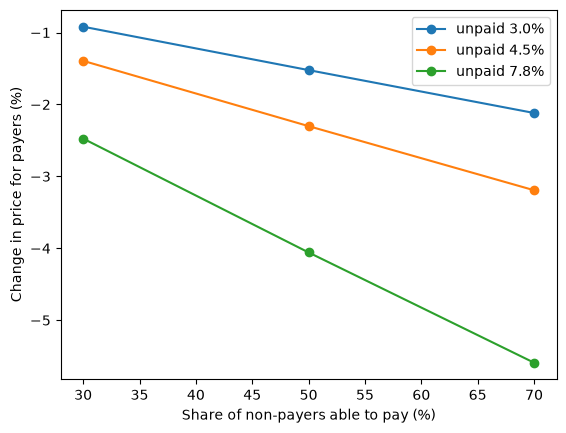

In [6]:
for u, g in grid.groupby("unpaid_share"):
    plt.plot(g["able_share"] * 100, g["change_vs_payers_only_pct"],
             marker="o", label=f"unpaid {u:.1%}")
plt.xlabel("Share of non-payers able to pay (%)")
plt.ylabel("Change in price for payers (%)")
plt.legend()
plt.show()

### What does the counterfactual price measure?
It asks what price per unit payers would face if all costs were recovered only from paying customers, and how that price changes if some non-payers who can afford it start paying. With R100 of costs, 90 units paid and 10 unpaid, payers face R1.11 a unit. If half of the unpaid units start paying, the price falls to R1.05, about 5% lower. It measures an economic burden. It is not the legal tariff, because NERSA sets the tariff from allowable revenue and forecast sales, so I cannot say payers are being overcharged. That is the question for Project B.

### What do the numbers say?
With the official average tariff at about 200 c/kWh, and 4.5% of revenue unpaid, payers would face about 209 c/kWh if costs were recovered from them alone. If half of the non-payers who can afford to pay did so, the price falls by about 2.3%, and about R8.7 billion a year would be recovered. Using the data-based shares from notebook 04 (50%, 81% and 99% able to pay), the price falls by 2.3% to 4.4%, and R8.7 to R17 billion would be recovered. Across the whole grid, the price falls by between about 1% and 8%. The effect is a few percent at most. This top-down figure (a share of all Eskom revenue) is a different measure from the bottom-up household estimate in notebook 06, and they will not match exactly, because Eskom's unpaid revenue also includes municipalities and other customers.

### Limits

1. The result depends on the unpaid share of revenue (3% to 7.8%). The 4.5% comes from R15.8 billion of revenue Eskom did not recognise in its FY2026 results, and I still need to verify it.
2. I treat the share of revenue unpaid as the share of volume unpaid, which is a simplification.
3. The sales volume (192,710 GWh) is a placeholder until I find it in NERSA's reasons for decision, so the cents-per-kWh figures are indicative.
4. It assumes costs are recovered only from payers. The approved tariff does not work that way, so this is a burden measure and not evidence of overcharging.
5. Able to pay does not mean willing to pay, and collection would never reach 100%.